# Entrenamiento YOLO local — Sistema IoT de seguridad vehicular (UCSM 2026)

**Equipo:** Intel i7-14650HX · 32 GB RAM · NVIDIA RTX 5060 Laptop (8 GB)

Ejecuta las celdas **en orden**, de arriba hacia abajo.

> ⚠️ La RTX 5060 es arquitectura *Blackwell*: necesita **PyTorch con CUDA 12.8 (cu128)**.
> Si instalas PyTorch normal, no reconocerá la GPU. La celda 2 instala la versión correcta.

**Antes de empezar:**
- Laptop **enchufada** a corriente y en modo **Máximo rendimiento**.
- Cierra programas pesados (la RAM ya está al 73 % en uso).

## 1. Verificar la GPU

In [1]:
!nvidia-smi

Sun Oct 11 18:47:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 617.14                 KMD Version: 617.14        CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5060 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   54C    P8              5W /   80W |     432MiB /   8151MiB |      2%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Instalar librerías (solo la primera vez)
El orden importa: primero PyTorch con CUDA 12.8, luego Ultralytics.
Al terminar, **reinicia el kernel** (menú *Kernel → Restart*) y sigue con la celda 3.

In [ ]:
%pip install --upgrade torch torchvision --index-url https://download.pytorch.org/whl/cu128
%pip install --upgrade ultralytics roboflow

## 3. Comprobar que PyTorch ve la GPU

In [1]:
import torch
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Arquitectura:", torch.cuda.get_device_capability(0))   # RTX 5060 -> (12, 0)
    print("VRAM: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
else:
    print("❌ No se detecta la GPU. Revisa la celda 2 (debe ser la versión cu128).")

PyTorch: 2.11.0+cu128
CUDA disponible: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Arquitectura: (12, 0)
VRAM: 8.5 GB


## 4. Descargar el dataset desde Roboflow
En Roboflow: **Versions → tu versión → Download Dataset → formato YOLOv8 → Show download code**.
Copia de ese código tu `api_key`, el nombre del workspace, del proyecto y el número de versión, y pégalos abajo.

In [4]:
import shutil, os
from roboflow import Roboflow

# borrar la descarga incompleta
if os.path.exists("./dataset_sv"):
    shutil.rmtree("./dataset_sv")

rf = Roboflow(api_key="R4fPPXiz9e2tWXD1EA7I")
project = rf.workspace("darwin-turpo-s-workspace").project("sv_ucsm")
version = project.version(1)
dataset = version.download("yolo26", location="./dataset_sv", overwrite=True)

print("Dataset en:", dataset.location)
print("Archivos:", os.listdir(dataset.location))

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to ./dataset_sv in yolo26::  27%|██▋       | 7713/28903 [00:02<00:07, 2678.35it/s]


FileNotFoundError: [Errno 2] No such file or directory: 'dataset_sv\\train\\images\\a-car-after-an-accident-with-a-broken-rear-window-broken-window-in-a-vehicle-the-wreckage-of-the-interior-of-a-modern-car-after-an-accident-a-detai-2JT2CFW_jpg.rf.3fc6cec5412b72cefba2bc80d0fc65c7.jpg'

In [5]:
import zipfile, os, re, shutil
from types import SimpleNamespace

zip_path = "dataset_sv/roboflow.zip"
out = os.path.abspath("ds")          # carpeta nueva con ruta corta

if os.path.exists(out):
    shutil.rmtree(out)

n = 0
with zipfile.ZipFile(zip_path) as z:
    for m in z.infolist():
        if m.is_dir():
            continue
        parts = m.filename.split("/")
        name = parts[-1]
        # nombre largo ...rf.<hash>.jpg  ->  <hash>.jpg  (igual para su .txt)
        r = re.search(r"\.rf\.([0-9a-fA-F]+)\.(\w+)$", name)
        if r:
            name = f"{r.group(1)}.{r.group(2)}"
        dest = os.path.join(out, *parts[:-1], name)
        os.makedirs(os.path.dirname(dest), exist_ok=True)
        with z.open(m) as src, open(dest, "wb") as dst:
            shutil.copyfileobj(src, dst)
        n += 1

print("Archivos extraídos:", n)
for s in ["train", "valid", "test"]:
    imgs = len(os.listdir(os.path.join(out, s, "images")))
    lbls = len(os.listdir(os.path.join(out, s, "labels")))
    print(f"{s}: {imgs} imágenes | {lbls} etiquetas")

dataset = SimpleNamespace(location=out)   # para que la celda 5 funcione igual

Archivos extraídos: 28903
train: 11353 imágenes | 11353 etiquetas
valid: 2113 imágenes | 2113 etiquetas
test: 983 imágenes | 983 etiquetas


## 5. Corregir rutas del `data.yaml`
El `data.yaml` de Roboflow trae rutas relativas que a veces fallan en Windows.
Esta celda las reemplaza por rutas absolutas y muestra las clases.

In [6]:
import os, yaml

root = os.path.abspath(dataset.location)
yaml_path = os.path.join(root, "data.yaml")
with open(yaml_path, encoding="utf-8") as f:
    data = yaml.safe_load(f)

data["path"]  = root
data["train"] = os.path.join(root, "train", "images")
data["val"]   = os.path.join(root, "valid", "images")
data["test"]  = os.path.join(root, "test", "images")

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(data, f, allow_unicode=True, sort_keys=False)

print("Número de clases:", data["nc"])
for i, n in enumerate(data["names"]):
    print(f"  {i:2d}  {n}")
for s in ["train", "valid", "test"]:
    print(s, len(os.listdir(os.path.join(root, s, "images"))), "imágenes")

Número de clases: 22
   0  Car
   1  Person
   2  Vandalism
   3  breaking_the_door
   4  broken_glass
   5  c0 - Safe Driving
   6  c1 - Texting
   7  c2 - Talking on the phone
   8  c3 - Operating the Radio
   9  c4 - Drinking
  10  c5 - Reaching Behind
  11  c6 - Hair and Makeup
  12  c7 - Talking to Passenger
  13  car
  14  car broken
  15  destroying
  16  glass shatter
  17  person
  18  suspicious
  19  theft
  20  theft-detection
  21  vehicle theft
train 11353 imágenes
valid 2113 imágenes
test 983 imágenes


## 6. Entrenar
- **Modelo:** `yolo26n.pt` (nano: el más liviano, ideal para la computadora embebida). Si da error de descarga, cambia a `yolo11n.pt`.
- **batch=16** cabe bien en 8 GB a 640 px. Si sale *CUDA out of memory*, bájalo a 8.
- **workers=4**: si la celda se queda congelada sin avanzar (pasa a veces en Windows), detén y pon `workers=0`.
- Los aumentos (flip, brillo, mosaic, etc.) los hace Ultralytics automáticamente en cada época, sin costo.
- Tiempo estimado: varias horas para 100 épocas con ~14 000 imágenes. `patience=20` lo detiene antes si ya no mejora.

In [7]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")      # alternativa: "yolo11n.pt"

results = model.train(
    data=yaml_path,
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,          # GPU RTX 5060
    workers=4,
    patience=20,
    cache=False,       # no cargar todo en RAM (14k imágenes llenarían la memoria)
    amp=True,          # precisión mixta: más rápido y menos VRAM
    # aumentos extra para simular la cámara de noche en el retrovisor
    hsv_v=0.5, fliplr=0.5, degrees=5, scale=0.5,
    project="runs_sv", name="yolo_sv",
    plots=True,
)

Ultralytics 8.4.175  Python-3.14.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Usuario\PycharmProjects\TRAIN_YOLO26\ds\data.yaml, degrees=5, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.5, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_sv,

### ¿Se cortó el entrenamiento? (apagón, cerraste la laptop, etc.)
Ejecuta esta celda para **continuar desde donde se quedó**, sin empezar de cero.

In [ ]:
# from ultralytics import YOLO
# model = YOLO("runs_sv/yolo_sv/weights/last.pt")
# model.train(resume=True)

## 7. Evaluar en el conjunto de PRUEBA (resultados para el Capítulo V)
Esto genera las métricas que van en tu **Tabla 22** (por clase) y la matriz de confusión (**Figura 19**).

In [10]:
from ultralytics import YOLO
import pandas as pd

best = YOLO("runs/detect/runs_sv/yolo_sv/weights/best.pt")
m = best.val(data=yaml_path, split="test", imgsz=640, batch=16, device=0,
             project="runs_sv", name="test_eval", plots=True)

print(f"Precisión (P): {m.box.mp:.3f}")
print(f"Exhaustividad (R): {m.box.mr:.3f}")
print(f"mAP@0.5: {m.box.map50:.3f}")
print(f"mAP@0.5:0.95: {m.box.map:.3f}")

# Tabla por clase
filas = []
for i, c in enumerate(m.box.ap_class_index):
    p, r, ap50, ap = m.box.class_result(i)
    filas.append({"Clase": best.names[int(c)], "P": round(p,3), "R": round(r,3),
                  "mAP@0.5": round(ap50,3), "mAP@0.5:0.95": round(ap,3)})
tabla = pd.DataFrame(filas)
ruta_csv = os.path.join(m.save_dir, "tabla22_metricas_por_clase.csv")
tabla.to_csv(ruta_csv, index=False, encoding="utf-8-sig"); print("Guardado en:", ruta_csv)
tabla

Ultralytics 8.4.175  Python-3.14.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8123MiB)
YOLO26n summary (fused): 121 layers, 2,394,838 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 410.8275.9 MB/s, size: 67.6 KB)
val: Scanning C:\Users\Usuario\PycharmProjects\TRAIN_YOLO26\ds\test\labels.cache... 983 images, 327 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 983/983 458.1Mit/s 0.0s
val: C:\Users\Usuario\PycharmProjects\TRAIN_YOLO26\ds\test\images\2718687e6431c2b0299797ac281a6533.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: C:\Users\Usuario\PycharmProjects\TRAIN_YOLO26\ds\test\images\7d66f34e25f434bf2d2b0baf154f87ae.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: C:\Users\Usuario\PycharmProjects\TRAIN_YOLO26\ds\test\images\a9efa5728d9badd43f75782cfe75679e.jpg: ignoring corrupt image/label: labels mix segment and detection rows
WARNING Box and segment counts should be equal, 

,Clase,P,R,mAP@0.5,mAP@0.5:0.95
0,Car,1.000,0.269,0.572,0.448
1,Person,0.746,0.345,0.652,0.322
2,Vandalism,0.852,0.269,0.495,0.160
3,breaking_the_door,0.387,0.500,0.620,0.193
4,c0 - Safe Driving,0.872,0.955,0.984,0.903
5,c1 - Texting,0.957,1.000,0.995,0.922
6,c2 - Talking on the phone,0.958,1.000,0.995,0.919
7,c3 - Operating the Radio,1.000,0.988,0.995,0.919
8,c4 - Drinking,0.943,1.000,0.954,0.872
9,c5 - Reaching Behind,0.940,1.000,0.993,0.825


In [14]:
import matplotlib
print(matplotlib.matplotlib_fname())

C:\Users\Usuario\PycharmProjects\TRAIN_YOLO26\.venv\Lib\site-packages\matplotlib\mpl-data\matplotlibrc


In [13]:
   import matplotlib
   print(matplotlib.get_configdir())

C:\Users\Usuario\.matplotlib


## 8. Probar el modelo en imágenes
Pon algunas fotos de prueba (idealmente tomadas con **tu cámara del retrovisor**) en una carpeta `pruebas/`.

In [11]:
import os
os.makedirs("pruebas", exist_ok=True)
best.predict(source="pruebas", conf=0.4, save=True, project="runs_sv", name="predicciones", device=0)
print("Resultados guardados en runs_sv/predicciones")

FileNotFoundError: No images or videos found in pruebas. Supported formats are:
images: {'heic', 'avif', 'tif', 'heif', 'webp', 'jpeg', 'mpo', 'png', 'tiff', 'jp2', 'bmp', 'dng', 'jpg'}
videos: {'wmv', 'gif', 'mov', 'm4v', 'webm', 'mp4', 'avi', 'mkv', 'ts', 'asf', 'mpg', 'mpeg'}

## 9. Agrupar las clases del modelo en los 4 eventos de riesgo (Tabla 17)
El modelo detecta las clases originales de Roboflow; esta función las traduce al evento del sistema.

In [12]:
EVENTO = {
    "person": "persona", "Person": "persona", "suspicious": "persona",
    "breaking_the_door": "manipulacion_puerta", "vehicle theft": "manipulacion_puerta",
    "theft": "manipulacion_puerta", "theft-detection": "manipulacion_puerta",
    "broken_glass": "ruptura_vidrio", "glass shatter": "ruptura_vidrio",
    "car broken": "ruptura_vidrio", "destroying": "ruptura_vidrio", "Vandalism": "ruptura_vidrio",
}
for n in best.names.values():
    if len(n) > 1 and n[0] == "c" and n[1].isdigit():      # c0 ... c7 (Distracted Driver)
        EVENTO[n] = "ingreso_no_autorizado"
# "car" y "Car" no generan evento

def eventos_en(imagen, conf=0.4):
    r = best.predict(imagen, conf=conf, device=0, verbose=False)[0]
    salida = []
    for b in r.boxes:
        clase = best.names[int(b.cls)]
        if clase in EVENTO:
            salida.append((EVENTO[clase], clase, round(float(b.conf), 2)))
    return salida

for f in os.listdir("pruebas")[:5]:
    print(f, "->", eventos_en(os.path.join("pruebas", f)))

## 10. Exportar para la computadora embebida
- **ONNX**: sirve para casi cualquier equipo (Raspberry Pi, mini PC, etc.).
- Si tu equipo embebido es una **NVIDIA Jetson**, exporta allí mismo a TensorRT (`format="engine"`).
- Para **Raspberry Pi**, NCNN suele ser el más rápido.

In [ ]:
best.export(format="onnx", imgsz=640, simplify=True)
# best.export(format="ncnn", imgsz=640)   # Raspberry Pi
print("Modelo exportado junto a best.pt en runs_sv/yolo_sv/weights/")

## Archivos para tu tesis
| Archivo | Uso en la tesis |
|---|---|
| `runs_sv/yolo_sv/results.png` | Figura 18 — curvas de pérdida y mAP |
| `runs_sv/test_eval/confusion_matrix.png` | Figura 19 — matriz de confusión |
| `runs_sv/tabla22_metricas_por_clase.csv` | Tabla 22 — métricas por clase |
| `runs_sv/yolo_sv/args.yaml` | Tabla 21 — hiperparámetros usados |
| `runs_sv/yolo_sv/weights/best.pt` | Modelo final para el prototipo |

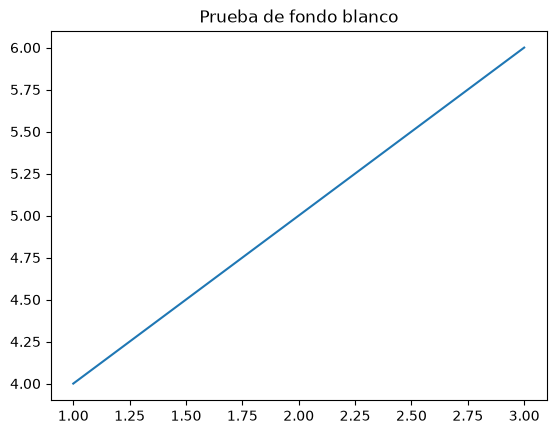

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.plot([1, 2, 3], [4, 5, 6])
ax.set_title("Prueba de fondo blanco")
plt.show()